**WINE CLASSIFICATION AND PREDICTION - MACHINE LEARNING MINI PROJECT**

**Algorithm**: simple linear regression , multiple linear regression , decision tree , k-nearest neighbors(KNN) , logistic regression , K-means clustering.

**Dataset**: Wine dataset (wine_dataset.csv).

**1.Import required libraries**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    r2_score,
    silhouette_score,
    adjusted_rand_score
)

**2.Load the Dataset**

In [5]:
# Load the Wine dataset
wine = load_wine()

# Convert into DataFrame
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Add target column
df["target"] = wine.target

# Display first five rows
print(df.head())

# Dataset information
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display target classes
print("\nTarget Classes:")
print(wine.target_names)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

**3. Separate input and output**

In [6]:
# Input features
X = df.drop("target", axis=1)

# Output label
y = df["target"]

print("Input Features:")
print(X.head())

print("\nOutput Labels:")
print(y.head())

Input Features:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0  

**4. Split the dataset**

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (142, 13)
Testing Data: (36, 13)


 **5. Feature scaling**

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Scale complete dataset for K-Means
X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed")

Feature Scaling Completed


**6. Apply Simple Linear Regression**

In [9]:
# Select one input feature
X_simple = df[["flavanoids"]]

# Output variable
y_reg = df["alcohol"]

# Split dataset
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_reg,
    test_size=0.2,
    random_state=42
)

# Create model
simple_model = LinearRegression()

# Train model
simple_model.fit(X_train_s, y_train_s)

# Predict
simple_pred = simple_model.predict(X_test_s)

# Evaluate
simple_mse = mean_squared_error(y_test_s, simple_pred)
simple_r2 = r2_score(y_test_s, simple_pred)

print("Simple Linear Regression")
print("Mean Squared Error:", round(simple_mse, 3))
print("R2 Score:", round(simple_r2, 3))

Simple Linear Regression
Mean Squared Error: 0.55
R2 Score: 0.078


**7. Apply Multiple Linear Regression**

In [10]:
# Input features excluding alcohol
X_multiple = df.drop(
    ["target", "alcohol"],
    axis=1
)

# Output variable
y_multiple = df["alcohol"]

# Split dataset
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiple, y_multiple,
    test_size=0.2,
    random_state=42
)

# Create model
multiple_model = LinearRegression()

# Train model
multiple_model.fit(X_train_m, y_train_m)

# Predict
multiple_pred = multiple_model.predict(X_test_m)

# Evaluate
multiple_mse = mean_squared_error(y_test_m, multiple_pred)
multiple_r2 = r2_score(y_test_m, multiple_pred)

print("Multiple Linear Regression")
print("Mean Squared Error:", round(multiple_mse, 3))
print("R2 Score:", round(multiple_r2, 3))

Multiple Linear Regression
Mean Squared Error: 0.186
R2 Score: 0.689


**8. Apply Decision Tree**

In [11]:
# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42
)

# Train model
decision_tree.fit(X_train, y_train)

# Predict
tree_pred = decision_tree.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, tree_pred)

print("Decision Tree Accuracy:",
      round(tree_accuracy * 100, 2), "%")

Decision Tree Accuracy: 94.44 %


**9. Apply K-Nearest Neighbors (KNN)**

In [12]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train model
knn.fit(X_train_scaled, y_train)

# Predict
knn_pred = knn.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 97.22 %


**10. Apply Logistic Regression**

In [13]:
# Create Logistic Regression model
logistic = LogisticRegression(max_iter=1000)

# Train model
logistic.fit(X_train_scaled, y_train)

# Predict
logistic_pred = logistic.predict(X_test_scaled)

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test, logistic_pred
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 97.22 %


**11. Apply K-Means Clustering**

In [14]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model
clusters = kmeans.fit_predict(X_scaled)

# Display cluster assignments
print("Cluster Assignments:")
print(clusters)

# Evaluate clustering
silhouette = silhouette_score(
    X_scaled, clusters
)

ari = adjusted_rand_score(y, clusters)

print("\nSilhouette Score:", round(silhouette, 3))
print("Adjusted Rand Index:", round(ari, 3))

Cluster Assignments:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Silhouette Score: 0.285
Adjusted Rand Index: 0.897


**12. Compare the algorithms**

Classification Algorithm Comparison:
          Algorithm  Accuracy (%)
      Decision Tree     94.444444
                KNN     97.222222
Logistic Regression     97.222222


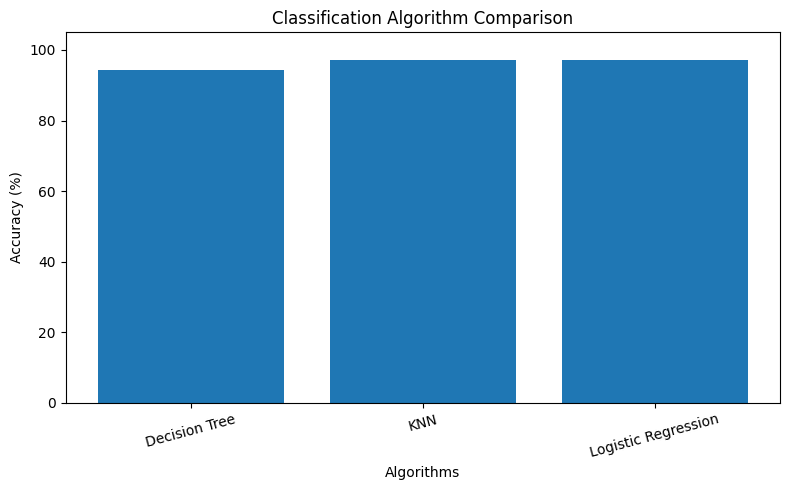


Regression Algorithm Comparison:
                 Algorithm      MSE  R2 Score
  Simple Linear Regression 0.550182  0.078477
Multiple Linear Regression 0.185716  0.688936


In [15]:
# Classification comparison
results = pd.DataFrame({
    "Algorithm": [
        "Decision Tree",
        "KNN",
        "Logistic Regression"
    ],
    "Accuracy (%)": [
        tree_accuracy * 100,
        knn_accuracy * 100,
        logistic_accuracy * 100
    ]
})

print("Classification Algorithm Comparison:")
print(results.to_string(index=False))

# Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(
    results["Algorithm"],
    results["Accuracy (%)"]
)

plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("Classification Algorithm Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Regression comparison
regression_results = pd.DataFrame({
    "Algorithm": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MSE": [
        simple_mse,
        multiple_mse
    ],
    "R2 Score": [
        simple_r2,
        multiple_r2
    ]
})

print("\nRegression Algorithm Comparison:")
print(regression_results.to_string(index=False))

**13. Classification reports**

In [16]:
print("Decision Tree Classification Report:")
print(classification_report(y_test, tree_pred))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, logistic_pred))

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        12
           1       0.88      1.00      0.93        14
           2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36


KNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96        14
           2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0

**Conclusion**

In this project, the Wine dataset was used to implement six Machine Learning algorithms: Simple Linear Regression, Multiple Linear Regression, Decision Tree, K-Nearest Neighbors (KNN), Logistic Regression and K-Means Clustering. The regression models were used to predict alcohol content, while the classification models were used to predict wine classes. K-Means was used to group similar wine samples into clusters. The performance of the models was evaluated using appropriate metrics to understand and compare their results. Thus, this project demonstrates the application of different Machine Learning algorithms on a single dataset.